# Checkpoint 04: Tối Ưu Hóa Chiến Lược Huấn Luyện (Advanced Training Strategies)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu khoa học:
1. Khắc phục các hạn chế kỹ thuật trong cấu hình huấn luyện của Baseline gốc (2 epochs ngắn ngủi, độ dài chuỗi max_length = 100 gây cắt cụt thông tin).
2. Mở rộng chiều dài chuỗi tối đa lên `max_length = 256` nhằm bao phủ hoàn chỉnh ngữ cảnh bình luận mạng xã hội, tận dụng tối đa giới hạn vị trí nhúng của PhoBERT.
3. Tăng thời lượng huấn luyện lên 8 epochs kết hợp cơ chế dừng sớm (Early Stopping với patience = 2) theo dõi trực tiếp chỉ số `eval_macro_f1`.
4. Áp dụng phân tầng tốc độ học (Differential Learning Rates): giữ tốc độ học nhỏ ($2 \times 10^{-5}$) cho backbone RoBERTa và tốc độ học lớn hơn ($1 \times 10^{-4}$) cho Classification Head.
5. Tối ưu hóa cập nhật trọng số với lịch trình Cosine Annealing with Warmup và tích lũy gradient (gradient_accumulation_steps = 2, effective batch size = 32).
6. Tự động phục hồi trọng số tối ưu nhất (`load_best_model_at_end = True`) tại điểm cực đại của Macro-F1 trên tập dev.
7. Xuất đầy đủ 4 tệp Mandatory Artifacts cùng biểu đồ Learning Curves vào `outputs/checkpoint04/`.

Ghi chú: Toàn bộ mã nguồn định nghĩa tối ưu hóa phân tầng, custom trainer, đồ thị học và đánh giá được tích hợp 100% trong notebook để chạy độc lập trên Google Colab.

In [1]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint04')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint04')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint04
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04


In [2]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q vncorenlp transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch


In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Thiết lập random seed thành công: {random_seed}')

Thiết lập random seed thành công: 42


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, null: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, null: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, null: {test_raw["free_text"].isna().sum()}')

Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, null: 2
- Dev:   2672 mẫu, null: 0
- Test:  6680 mẫu, null: 0


## 2. Chuẩn Bị Dữ Liệu và Tách Từ Bằng VnCoreNLP


In [5]:
import os
import urllib.request
from vncorenlp import VnCoreNLP

text_column = 'free_text'
label_column = 'label_id'

# 1. Làm sạch dữ liệu thiếu (Null/NaN)
train_clean = train_raw.dropna(subset=[text_column, label_column]).copy()
dev_clean = dev_raw.dropna(subset=[text_column, label_column]).copy()
test_clean = test_raw.dropna(subset=[text_column, label_column]).copy()

train_clean[label_column] = train_clean[label_column].astype(int)
dev_clean[label_column] = dev_clean[label_column].astype(int)
test_clean[label_column] = test_clean[label_column].astype(int)

# 2. Khởi tạo VnCoreNLP Word Segmenter theo chuẩn bài báo gốc
vncorenlp_dir = 'vncorenlp'
if not os.path.exists(os.path.join(vncorenlp_dir, 'VnCoreNLP-1.1.1.jar')):
    if 'project_dir' in globals() and os.path.exists(os.path.join(project_dir, 'vncorenlp', 'VnCoreNLP-1.1.1.jar')):
        vncorenlp_dir = os.path.join(project_dir, 'vncorenlp')

model_dir = os.path.join(vncorenlp_dir, 'models', 'wordsegmenter')
os.makedirs(model_dir, exist_ok=True)
jar_path = os.path.join(vncorenlp_dir, 'VnCoreNLP-1.1.1.jar')
base_url = 'https://raw.githubusercontent.com/vncorenlp/VnCoreNLP/master/'

for file_path, rel in [
    (jar_path, 'VnCoreNLP-1.1.1.jar'),
    (os.path.join(model_dir, 'vi-vocab'), 'models/wordsegmenter/vi-vocab'),
    (os.path.join(model_dir, 'wordsegmenter.rdr'), 'models/wordsegmenter/wordsegmenter.rdr'),
]:
    if not os.path.exists(file_path):
        urllib.request.urlretrieve(base_url + rel, file_path)

rdrsegmenter = VnCoreNLP(jar_path, annotators='wseg', max_heap_size='-Xmx500m')


def segment_text(text):
    if not isinstance(text, str) or not text.strip():
        return ''
    try:
        sentences = rdrsegmenter.tokenize(text)
        return ' '.join([' '.join(s) for s in sentences])
    except Exception:
        return text


# 3. Tách từ trên 3 tập dữ liệu
print('Bắt đầu tách từ bằng VnCoreNLP (Word Segmentation)...')
train_X = [segment_text(t) for t in train_clean[text_column]]
train_y = train_clean[label_column].to_numpy()

dev_X = [segment_text(t) for t in dev_clean[text_column]]
dev_y = dev_clean[label_column].to_numpy()

test_X = [segment_text(t) for t in test_clean[text_column]]
test_y = test_clean[label_column].to_numpy()

print(f'- Train : {len(train_X):,} mẫu đã tách từ')
print(f'- Dev   : {len(dev_X):,} mẫu đã tách từ')
print(f'- Test  : {len(test_X):,} mẫu đã tách từ')


Kích thước tập dữ liệu sẵn sàng cho mã hóa:
- Train: 24046 mẫu
- Dev:   2672 mẫu
- Test:  6680 mẫu


## 3. Định Nghĩa Lớp BuildDataset và Mã Hóa Với Độ Dài Mở Rộng (max_length = 256)

In [6]:
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2672
Kích thước tập test sau mã hóa:  6680


## 4. Cấu Hình Phân Tầng Tốc Độ Học (Differential Learning Rates) và Trainer Tùy Biến

In [7]:
from torch.optim import AdamW
from transformers import Trainer, get_cosine_schedule_with_warmup


class DifferentialTrainer(Trainer):
    """Lớp Trainer cấu hình phân tầng tốc độ học và lịch trình Cosine Annealing with Warmup."""

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        decay_parameters = [p for n, p in self.model.named_parameters() if not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        no_decay_parameters = [p for n, p in self.model.named_parameters() if any(nd in n for nd in ['bias', 'LayerNorm.weight'])]

        roberta_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        roberta_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]

        optimizer_grouped_parameters = [
            {'params': roberta_decay, 'lr': 2e-5, 'weight_decay': 0.01},
            {'params': roberta_no_decay, 'lr': 2e-5, 'weight_decay': 0.0},
            {'params': classifier_decay, 'lr': 1e-4, 'weight_decay': 0.01},
            {'params': classifier_no_decay, 'lr': 1e-4, 'weight_decay': 0.0},
        ]

        self.optimizer = AdamW(optimizer_grouped_parameters)
        warmup_steps = int(num_training_steps * 0.10)
        self.lr_scheduler = get_cosine_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=num_training_steps,
        )
        print(f'Đã khởi tạo Optimizer phân tầng (lr_roberta=2e-5, lr_head=1e-4, warmup_steps={warmup_steps})')
        return self.optimizer, self.lr_scheduler

print('Định nghĩa DifferentialTrainer thành công.')

Định nghĩa DifferentialTrainer thành công.


## 5. Cấu Hình Siêu Tham Số Huấn Luyện Nâng Cao và Dừng Sớm (Early Stopping)

In [8]:
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
weight_decay = 0.01

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, EarlyStoppingCallback, TrainingArguments


def compute_metrics_eval(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)
    return {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }


model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name, num_labels=num_labels)

training_args = TrainingArguments(
    output_dir=checkpoints_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    weight_decay=weight_decay,
    do_eval=True,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    seed=random_seed,
)

trainer = DifferentialTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Khởi tạo DifferentialTrainer thành công cho Checkpoint 04.')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Khởi tạo DifferentialTrainer thành công cho Checkpoint 04.


## 6. Huấn Luyện Mô Hình và Lưu Checkpoint Tối Ưu

In [9]:
print('Bắt đầu huấn luyện Checkpoint 04 (Advanced Training Strategies)...')
train_result = trainer.train()

save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)
print(f'Đã lưu mô hình tốt nhất tại: {save_model_dir}')

Bắt đầu huấn luyện Checkpoint 04 (Advanced Training Strategies)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.736451,0.395099,0.858907,0.668743,0.548999,0.559281,0.858907,0.933245,0.188235,0.556364
2,0.556035,0.426669,0.868638,0.723034,0.591837,0.631259,0.868638,0.933480,0.389439,0.570858
3,0.461279,0.435191,0.864147,0.678001,0.682725,0.677043,0.864147,0.934524,0.512605,0.584000
4,0.380900,0.482792,0.866392,0.681107,0.651183,0.664292,0.866392,0.934448,0.469974,0.588454
5,0.237838,0.567386,0.870883,0.705200,0.646101,0.669546,0.870883,0.936618,0.514286,0.557734


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình tốt nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint04/final_model


## 7. Đánh Giá Trên Tập Test Độc Lập

In [10]:
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score


def evaluate_predictions(y_true, y_pred, class_names=None):
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    return {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }


print('Thực hiện dự đoán với mô hình Checkpoint 04 trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 04)')
print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với mô hình Checkpoint 04 trên tập kiểm tra...


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 04)
Accuracy (Độ chính xác tổng thể):  0.8590
Macro-Precision (Độ chuẩn xác):   0.6481
Macro-Recall (Độ nhạy):           0.6565
Macro-F1 Score (Chỉ số chính):    0.6460
Micro-F1 Score:                   0.8590
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9374, Recall = 0.9281, F1 = 0.9327
- offensive: Precision = 0.3706, Recall = 0.5225, F1 = 0.4336
- hate     : Precision = 0.6364, Recall = 0.5189, F1 = 0.5717
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9374    0.9281    0.9327      5548
   offensive     0.3706    0.5225    0.4336       444
        hate     0.6364    0.5189    0.5717       688

    accuracy                         0.8590      6680
   macro avg     0.6481    0.6565    0.6460      6680
weighted avg     0.8687    0.8590    0.8623      6680



## 8. Trực Quan Hóa Đồ Thị Học (Learning Curves) và Ma Trận Nhầm Lẫn

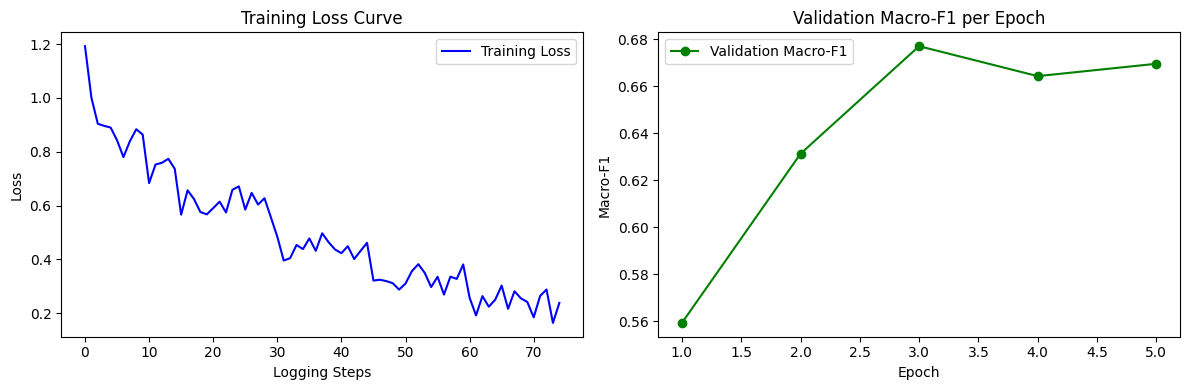

Đã lưu đồ thị học tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/learning_curves_checkpoint04.png


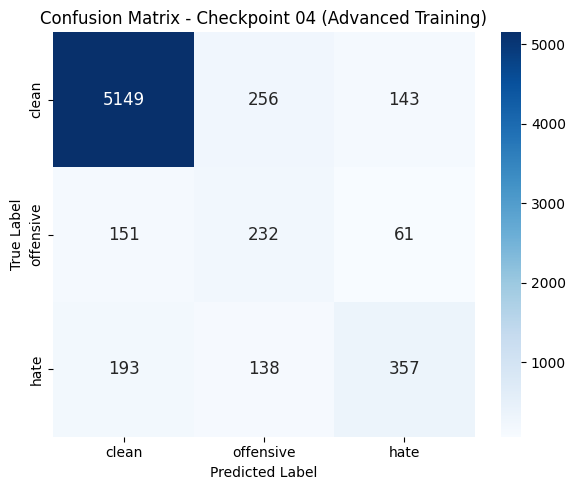

Đã lưu ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/confusion_matrix_checkpoint04.png


In [11]:
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint04.png')
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint04.png')

import matplotlib.pyplot as plt
import seaborn as sns

# Vẽ đồ thị tiến trình học
log_history = trainer.state.log_history
train_loss = [x['loss'] for x in log_history if 'loss' in x]
eval_f1 = [x['eval_macro_f1'] for x in log_history if 'eval_macro_f1' in x]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
if train_loss:
    ax1.plot(train_loss, label='Training Loss', color='blue')
    ax1.set_title('Training Loss Curve')
    ax1.set_xlabel('Logging Steps')
    ax1.set_ylabel('Loss')
    ax1.legend()
if eval_f1:
    ax2.plot(range(1, len(eval_f1) + 1), eval_f1, label='Validation Macro-F1', color='green', marker='o')
    ax2.set_title('Validation Macro-F1 per Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Macro-F1')
    ax2.legend()
plt.tight_layout()
plt.savefig(curves_output_path, dpi=300)
plt.show()
print(f'Đã lưu đồ thị học tại: {curves_output_path}')

# Vẽ ma trận nhầm lẫn
df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, cmap='Blues', fmt='d', cbar=True, ax=ax_cm, annot_kws={'size': 12})
ax_cm.set_title('Confusion Matrix - Checkpoint 04 (Advanced Training)')
ax_cm.set_xlabel('Predicted Label')
ax_cm.set_ylabel('True Label')
plt.tight_layout()
plt.savefig(cm_output_path, dpi=300)
plt.show()
print(f'Đã lưu ma trận nhầm lẫn tại: {cm_output_path}')

## 9. Xuất Các Tệp Kết Quả Chuẩn Hóa (Mandatory Artifacts Export)

In [13]:
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

test_ids = test_raw['id'] if 'id' in test_raw.columns else list(range(len(test_y)))
test_texts = test_raw['free_text'].tolist() if len(test_raw) == len(test_y) else test_X

df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_texts,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

report_dict = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/predictions.csv
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint04/classification_report.csv
